# TASK 05 - CNN From Scratch Experiment

Notebook ini menyiapkan baseline CNN tanpa pretrained weights untuk DSC 2026 Waste Classification. Jalankan cell secara manual dari atas ke bawah. Tidak ada training, resume, continued training, evaluasi validation penuh, maupun internal test yang berjalan otomatis.

**Batas data:** hanya split aktif TASK 02E dari V1/train. V1/test, V5, dan record label-noise yang telah dikeluarkan tidak digunakan.

## 1. Experiment Overview

Baseline memakai empat convolutional block dengan Batch Normalization, ReLU, Max Pooling, Adaptive Average Pooling, Dropout, dan classifier head ringan. Konfigurasi ditujukan untuk dataset train 1.340 gambar dan GPU 4 GB VRAM. Jumlah output selalu mengikuti class mapping manifest aktif.

## 2. Library Imports

Import mencakup library standar, visualisasi, PyTorch, serta modul reusable TASK 03-04. Import tidak memulai training.

In [10]:
from __future__ import annotations

import csv
import json
import random
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from PIL import Image
from torch import nn


def find_project_root(start: Path) -> Path:
    for candidate in (start.resolve(), *start.resolve().parents):
        if (candidate / "src").is_dir() and (candidate / "configs").is_dir() and (candidate / "data").is_dir():
            return candidate
    raise RuntimeError("Project root tidak ditemukan. Buka notebook dari root proyek atau notebooks/.")


PROJECT_ROOT = find_project_root(Path.cwd())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print(f"Project root: {PROJECT_ROOT}")
print(f"Python: {sys.version.split()[0]}")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA tersedia: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Project root: D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste_Classification
Python: 3.11.9
PyTorch: 2.10.0+cu128
CUDA tersedia: True
GPU: NVIDIA GeForce RTX 3050 Laptop GPU


In [5]:
from src.callbacks.early_stopping import EarlyStopping
from src.callbacks.lr_scheduler import build_scheduler
from src.callbacks.model_checkpoint import load_checkpoint
from src.callbacks.training_manager import TrainingManager
from src.data.dataloader import create_dataloader
from src.data.preprocessing import load_active_class_mapping, resolve_model_config
from src.evaluation.visualization import load_history, plot_learning_curves
from src.training.fine_tuning import load_best_checkpoint_for_fine_tuning
from src.training.resume import resume_from_checkpoint
from src.training.validate import validate_one_epoch

print("API TASK 03-04 berhasil diimpor.")

API TASK 03-04 berhasil diimpor.


## 3. Project Path & Environment Validation

Root proyek dicari tanpa path absolut. Bila GPU 4 GB mengalami CUDA out of memory, ubah batch size menjadi 8 atau 4 dan buat ulang DataLoader serta manager. Perubahan hanya berlaku di notebook ini, bukan YAML global.

## 4. Experiment Configuration

Konfigurasi eksperimen berada di notebook agar perubahan hyperparameter tidak mengubah YAML global atau source code bersama.

In [3]:
SEED = 42
EXPERIMENT_ID = "cnn_scratch_baseline_v1"  # Ganti untuk eksperimen baru agar artefak tidak tertimpa.
CONFIG = {
    "model_type": "cnn", "image_size": (224, 224), "batch_size": 16, "max_epochs": 100,
    "learning_rate": 1e-3, "weight_decay": 1e-4, "num_workers": 0,
    "pin_memory": torch.cuda.is_available(), "augmentation_enabled": True,
    "amp_enabled": torch.cuda.is_available(), "gradient_accumulation_steps": 1,
    "gradient_clip_norm": 1.0, "dropout": 0.40,
}
EARLY_STOPPING_CONFIG = {"monitor": "val_loss", "mode": "min", "patience": 10, "min_delta": 0.001}
SCHEDULER_CONFIG = {"name": "reduce_on_plateau", "monitor": "val_loss", "mode": "min", "factor": 0.5, "patience": 4, "min_lr": 1e-6}
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(SEED)
print(json.dumps({**CONFIG, "device": str(DEVICE)}, indent=2, default=str))

{
  "model_type": "cnn",
  "image_size": [
    224,
    224
  ],
  "batch_size": 16,
  "max_epochs": 100,
  "learning_rate": 0.001,
  "weight_decay": 0.0001,
  "num_workers": 0,
  "pin_memory": true,
  "augmentation_enabled": true,
  "amp_enabled": true,
  "gradient_accumulation_steps": 1,
  "gradient_clip_norm": 1.0,
  "dropout": 0.4,
  "device": "cuda"
}


## 5. Dataset & Class Mapping Validation

Cell ini membaca manifest aktif saja. Ia memastikan seluruh sumber berasal dari `data/extracted/v1/train`, class mapping konsisten, dan tidak ada referensi V1/test atau V5. Internal test hanya divalidasi sebagai split tetap; notebook ini tidak membuat loader internal test untuk pemilihan model.

In [4]:
MANIFEST_PATH = PROJECT_ROOT / "data" / "metadata" / "split_manifest.csv"
with MANIFEST_PATH.open(encoding="utf-8", newline="") as handle:
    manifest_rows = list(csv.DictReader(handle))

class_mapping = load_active_class_mapping(PROJECT_ROOT)
class_names = [name for name, _ in sorted(class_mapping.items(), key=lambda item: item[1])]
split_counts = Counter(row["split"] for row in manifest_rows)
class_by_split = {split: Counter(row["class_name"] for row in manifest_rows if row["split"] == split) for split in ("train", "val", "test_internal")}

assert split_counts == {"train": 1340, "val": 383, "test_internal": 191}
assert all(row["source_relative_path"].startswith("data/extracted/v1/train/") for row in manifest_rows)
assert not any("/test/" in row["source_relative_path"] or "/v5/" in row["source_relative_path"] for row in manifest_rows)
assert set(class_mapping) == set(row["class_name"] for row in manifest_rows)

print(f"Class mapping: {class_mapping}")
print(f"Jumlah kelas: {len(class_mapping)}")
pd.DataFrame(class_by_split).fillna(0).astype(int).loc[class_names]

Class mapping: {'cardboard': 0, 'electronic': 1, 'foodwaste': 2, 'glass': 3, 'metal': 4, 'paper': 5, 'plastic': 6, 'textile': 7}
Jumlah kelas: 8


,train,val,test_internal
cardboard,183,52,26
electronic,143,41,20
foodwaste,172,49,24
glass,145,41,21
metal,167,48,24
paper,156,45,22
plastic,222,64,32
textile,152,43,22


## 6. Model-Aware Preprocessing & Augmentation

Profil CNN TASK 03 menggunakan RGB, direct resize 224x224, tensor CHW `float32`, scaling `[0, 1]`, dan tanpa normalisasi tambahan pada baseline. Augmentasi on-the-fly hanya aktif untuk train; validation deterministik.

In [5]:
cnn_preprocessing = resolve_model_config("cnn", project_root=PROJECT_ROOT)
assert tuple(cnn_preprocessing["image_size"]) == CONFIG["image_size"]
assert cnn_preprocessing["normalization"] is None
print(json.dumps(cnn_preprocessing, indent=2, default=str))

{
  "color_mode": "RGB",
  "image_size": [
    224,
    224
  ],
  "resize_mode": "direct",
  "interpolation": "bilinear",
  "pixel_scaling": "zero_one",
  "normalization": null,
  "model_type": "cnn",
  "framework": "custom_pytorch",
  "pretrained": false,
  "metadata_priority": "config",
  "weights_name": null,
  "augmentation": {
    "enabled": true,
    "profile": "cnn_standard"
  }
}


## 7. DataLoader Initialization

Loader memakai API manifest-backed TASK 04. Train memakai shuffle dan augmentasi bila aktif; validation tidak memakai augmentasi acak. File gambar sumber dan manifest tidak diubah.

In [6]:
train_loader = create_dataloader(
    "train", CONFIG["model_type"], batch_size=CONFIG["batch_size"], seed=SEED,
    num_workers=CONFIG["num_workers"], pin_memory=CONFIG["pin_memory"], project_root=PROJECT_ROOT,
    augmentation_enabled=CONFIG["augmentation_enabled"],
)
val_loader = create_dataloader(
    "val", CONFIG["model_type"], batch_size=CONFIG["batch_size"], seed=SEED,
    num_workers=CONFIG["num_workers"], pin_memory=CONFIG["pin_memory"], project_root=PROJECT_ROOT,
    augmentation_enabled=False,
)
assert train_loader.dataset.class_to_idx == val_loader.dataset.class_to_idx == class_mapping
print(f"Train samples: {len(train_loader.dataset)} | Validation samples: {len(val_loader.dataset)}")
print(f"Batch size: {CONFIG['batch_size']} | Device: {DEVICE}")

Train samples: 1340 | Validation samples: 383
Batch size: 16 | Device: cuda


## 8. Dataset Preview

Preview ini menggunakan batch train yang dapat mengandung augmentasi acak. Ia tidak menjalankan training dan tidak menyimpan gambar hasil augmentasi permanen.

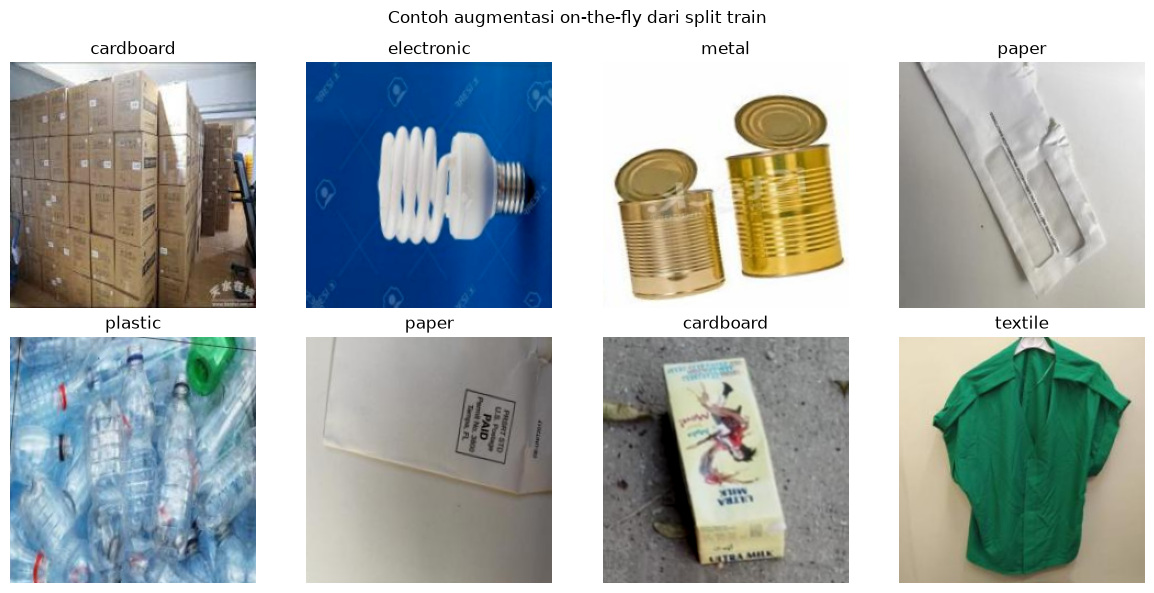

In [7]:
images, labels = next(iter(train_loader))
figure, axes = plt.subplots(2, 4, figsize=(12, 6))
for axis, image_tensor, label in zip(axes.flat, images[:8], labels[:8]):
    axis.imshow(image_tensor.permute(1, 2, 0).clamp(0, 1).numpy())
    axis.set_title(class_names[int(label)])
    axis.axis("off")
figure.suptitle("Contoh augmentasi on-the-fly dari split train")
figure.tight_layout()
plt.show()

## 9. CNN Architecture Definition

Empat block konvolusi menggunakan kanal 32->64->128->192. Batch normalization menstabilkan optimisasi; max pooling menurunkan resolusi; adaptive average pooling mencegah classifier terlalu besar; dropout 0,40 menjadi regularisasi awal. Model ini tidak memakai pretrained weights.

In [8]:
from src.models import CNNFromScratch

model = CNNFromScratch(num_classes=len(class_mapping), dropout=CONFIG["dropout"])
parameter_count = sum(parameter.numel() for parameter in model.parameters())
with torch.inference_mode():
    sanity_output = model(torch.zeros(2, 3, *CONFIG["image_size"]))
assert sanity_output.shape == (2, len(class_mapping))
print(model)
print(f"Trainable parameters: {parameter_count:,}")
print(f"Synthetic output shape: {tuple(sanity_output.shape)}")


CNNFromScratch(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
      (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU

## 10. Model Summary & Parameter Count

Parameter count di atas berasal dari model CNN yang baru dibuat dan tensor sintetis. Ini bukan hasil training atau inference dataset. Output classifier divalidasi terhadap delapan kelas dari manifest.

## 11. Loss Function, Optimizer & Scheduler

Baseline menggunakan `CrossEntropyLoss`, AdamW (`lr=0.001`, `weight_decay=0.0001`), dan ReduceLROnPlateau. Scheduler dan callback berasal dari utilitas TASK 04; tidak ada training loop yang diimplementasikan ulang di notebook.

In [9]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model.parameters(), lr=CONFIG["learning_rate"], weight_decay=CONFIG["weight_decay"]
)
scheduler, scheduler_kind = build_scheduler(optimizer, SCHEDULER_CONFIG)
print(f"Optimizer: {optimizer.__class__.__name__} | Scheduler: {scheduler.__class__.__name__}")

Optimizer: AdamW | Scheduler: ReduceLROnPlateau


## 12. Early Stopping & Model Checkpoint Configuration

Best checkpoint dipilih berdasarkan `val_loss`; last checkpoint menyimpan state untuk resume. Kedua artefak tersimpan per experiment ID saat training manual dijalankan.

In [10]:
early_stopping = EarlyStopping(**EARLY_STOPPING_CONFIG)
manager = TrainingManager(
    model=model, optimizer=optimizer, criterion=criterion, class_mapping=class_mapping,
    model_identifier="cnn_from_scratch", experiment_id=EXPERIMENT_ID, project_root=PROJECT_ROOT,
    device=DEVICE, scheduler=scheduler, scheduler_kind=scheduler_kind, early_stopping=early_stopping,
    training_config={**CONFIG, "scheduler": SCHEDULER_CONFIG, "early_stopping": EARLY_STOPPING_CONFIG},
    seed=SEED,
)
print(f"Best checkpoint: {manager.checkpoints.best_path}")
print(f"Last checkpoint: {manager.checkpoints.last_path}")

Best checkpoint: D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste_Classification\models\checkpoints\cnn_scratch_baseline_v1\best.pt
Last checkpoint: D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste_Classification\models\checkpoints\cnn_scratch_baseline_v1\last.pt


## 13. Training Execution Cell - Manual Opt-In

Set `RUN_TRAINING=True` hanya setelah memeriksa konfigurasi dan GPU memory. Bila CUDA OOM, turunkan batch size ke 8 atau 4, buat ulang loader/manager, lalu coba manual. Codex tidak menjalankan cell ini.

In [ ]:
RUN_TRAINING = False

if RUN_TRAINING:
    try:
        history = manager.fit(
            train_loader, val_loader, max_epochs=CONFIG["max_epochs"], amp_enabled=CONFIG["amp_enabled"],
            gradient_accumulation_steps=CONFIG["gradient_accumulation_steps"],
            gradient_clip_norm=CONFIG["gradient_clip_norm"], show_progress=True,
        )
        print(f"Training selesai pada {len(history)} epoch. Best epoch: {manager.early_stopping.best_epoch}")
    except torch.OutOfMemoryError as error:
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
        print("CUDA out of memory. Turunkan batch_size ke 8 atau 4, buat ulang loader/manager, lalu coba manual.")
        raise error
else:
    print("Training tidak dijalankan. Set RUN_TRAINING=True secara manual untuk memulai eksperimen.")

Training:   0%|          | 0/84 [00:00<?, ?it/s]

Training:   0%|          | 0/84 [00:00<?, ?it/s]

Training:   0%|          | 0/84 [00:00<?, ?it/s]

Training:   0%|          | 0/84 [00:00<?, ?it/s]

Training:   0%|          | 0/84 [00:00<?, ?it/s]

Training:   0%|          | 0/84 [00:00<?, ?it/s]

... (66 outputs left out)

Training:   0%|          | 0/84 [00:00<?, ?it/s]

Training:   0%|          | 0/84 [00:00<?, ?it/s]

Training:   0%|          | 0/84 [00:00<?, ?it/s]

Training selesai pada 75 epoch. Best epoch: 64


## 14. Training History & Progress Monitoring

`TrainingManager` menyimpan epoch, train loss/accuracy, validation loss/accuracy/macro-F1, learning rate, durasi, best epoch, checkpoint status, dan early stopping status pada `outputs/metrics/` serta `outputs/logs/`. Cell ini hanya membaca history nyata.

In [12]:
metrics_path = PROJECT_ROOT / "outputs" / "metrics" / f"{EXPERIMENT_ID}.json"
if metrics_path.is_file():
    actual_history = load_history(metrics_path)
    display(pd.DataFrame(actual_history))
else:
    actual_history = []
    print("Belum ada metrics history untuk experiment ID ini. Jalankan cell training manual terlebih dahulu.")

,epoch,train_loss,train_accuracy,val_loss,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,learning_rates,epoch_seconds,best_epoch,early_stopping,early_stopping_reason,checkpoint_best_saved,checkpoint_last
0,0,1.861952,0.291045,1.839558,0.336815,0.314834,0.322502,0.261436,[0.001],12.084566,0,False,NaN,True,D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste...
1,1,1.786788,0.338806,1.796513,0.308094,0.283874,0.321366,0.249382,[0.001],9.718205,1,False,NaN,True,D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste...
2,2,1.712283,0.344776,1.819451,0.352480,0.325092,0.346737,0.311200,[0.001],9.384995,1,False,NaN,False,D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste...
3,3,1.658992,0.371642,1.590310,0.412533,0.412433,0.406364,0.384088,[0.001],9.179352,3,False,NaN,True,D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste...
4,4,1.614446,0.410448,1.622596,0.415144,0.388143,0.410353,0.377853,[0.001],9.127942,3,False,NaN,False,D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70,70,1.042953,0.645522,1.273091,0.597911,0.589722,0.601026,0.591376,[0.000016],9.257330,64,False,NaN,False,D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste...
71,71,1.001032,0.654478,1.283463,0.574413,0.580820,0.574365,0.569737,[0.000016],9.198006,64,False,NaN,False,D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste...
72,72,0.994246,0.666418,1.284908,0.597911,0.604475,0.598069,0.593049,[0.000016],9.227981,64,False,NaN,False,D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste...
73,73,1.025233,0.640299,1.281117,0.592689,0.588830,0.594314,0.586373,[0.000016],9.453815,64,False,NaN,False,D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste...


## 15. Training vs Validation Learning Curves

Grafik mencakup loss, accuracy, learning rate, macro F1, best epoch, dan marker early stopping bila ada. Grafik disimpan pada `outputs/figures/` hanya jika history nyata tersedia.

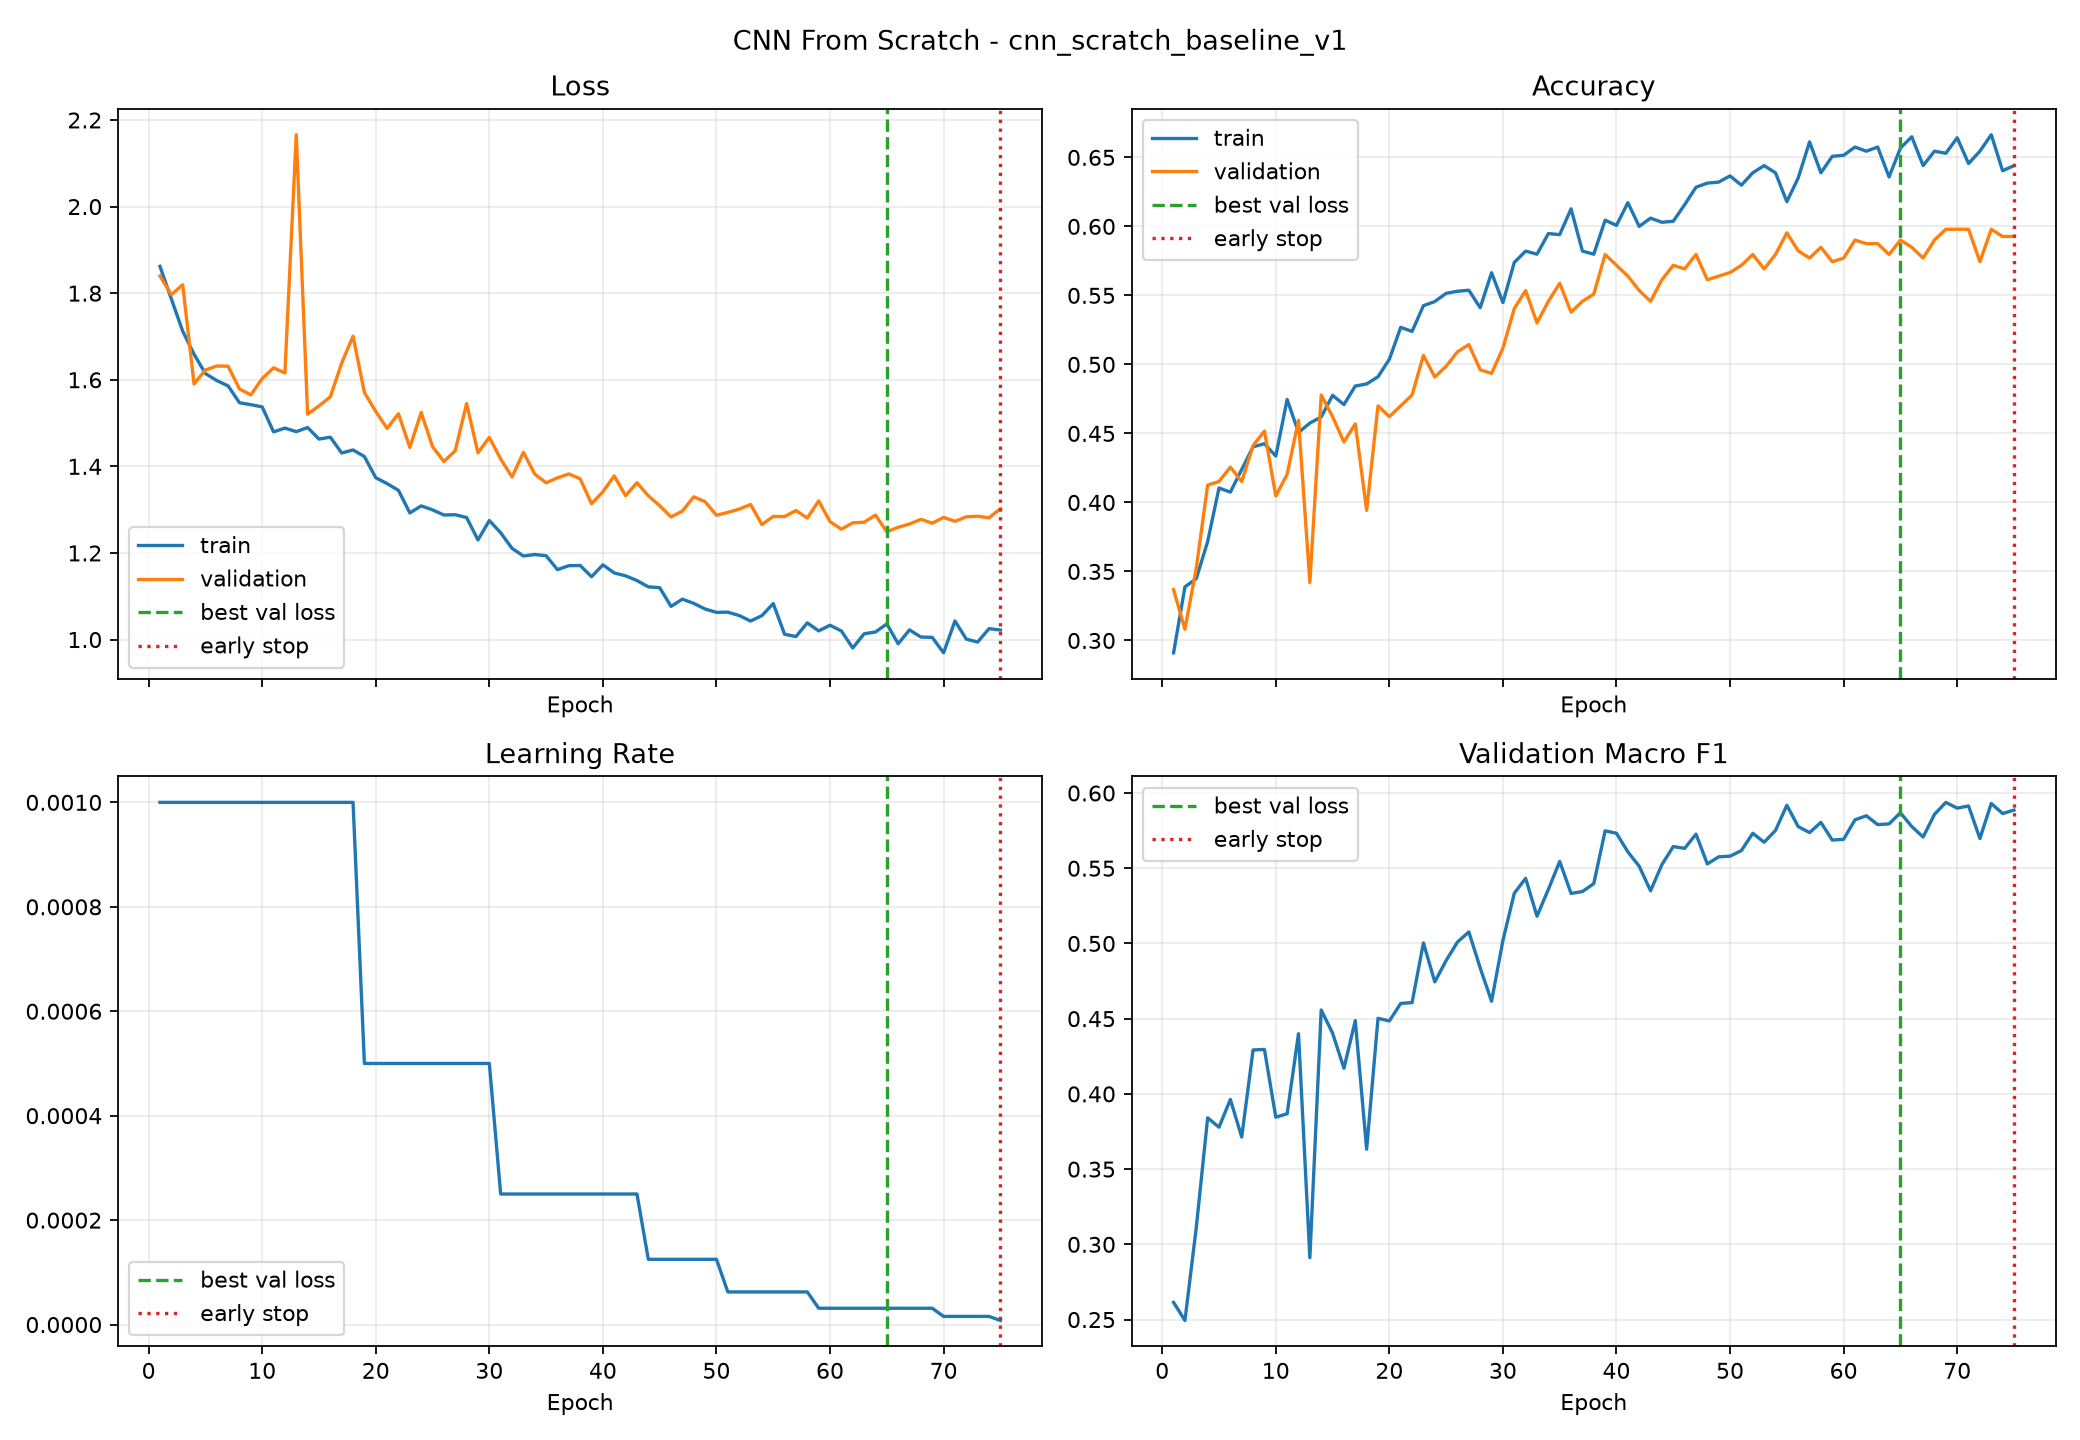

In [13]:
curve_path = PROJECT_ROOT / "outputs" / "figures" / f"{EXPERIMENT_ID}_learning_curves.png"
if actual_history:
    plot_learning_curves(actual_history, curve_path, title=f"CNN From Scratch - {EXPERIMENT_ID}")
    display(Image.open(curve_path))
else:
    print("Learning curve belum tersedia karena training belum dijalankan.")

## 16. Best Checkpoint Summary

Ringkasan checkpoint tampil hanya bila `best.pt` sudah ada. Checkpoint terbaik tidak diasumsikan sebagai accuracy tertinggi karena kebijakan baseline memonitor validation loss.

In [14]:
if manager.checkpoints.best_path.is_file():
    checkpoint_summary = load_checkpoint(manager.checkpoints.best_path, map_location="cpu")
    display(pd.Series({key: checkpoint_summary.get(key) for key in (
        "epoch", "best_epoch", "best_metric", "monitor", "model_identifier", "seed"
    )}))
else:
    print("Best checkpoint belum tersedia. Jalankan training manual terlebih dahulu.")

epoch                             64
best_epoch                        64
best_metric                 1.248915
monitor                     val_loss
model_identifier    cnn_from_scratch
seed                              42
dtype: object

## 17. Validation Classification Report

Evaluation berikut hanya menggunakan validation set dan best checkpoint. Internal test tidak dipakai untuk tuning hyperparameter atau checkpoint selection.

In [20]:
RUN_VALIDATION_EVALUATION = True
validation_metrics = None

if RUN_VALIDATION_EVALUATION:
    if not manager.checkpoints.best_path.is_file():
        raise FileNotFoundError("Best checkpoint belum tersedia. Jalankan training manual terlebih dahulu.")
    best_payload = load_checkpoint(manager.checkpoints.best_path, map_location=DEVICE)
    model.load_state_dict(best_payload["model_state_dict"])
    model.to(DEVICE)
    validation_metrics = validate_one_epoch(model, val_loader, criterion, class_mapping, DEVICE, show_progress=True)
    print(json.dumps({key: validation_metrics[key] for key in (
        "loss", "accuracy", "macro_precision", "macro_recall", "macro_f1", "sample_count"
    )}, indent=2))
    display(pd.DataFrame(validation_metrics["classification_report"]).T)
else:
    print("Validation evaluation tidak dijalankan. Set RUN_VALIDATION_EVALUATION=True setelah training.")

Validation:   0%|          | 0/24 [00:00<?, ?it/s]

{
  "loss": 1.2489149981316947,
  "accuracy": 0.5900783289817232,
  "macro_precision": 0.5936409911186697,
  "macro_recall": 0.5912422597012138,
  "macro_f1": 0.586874883272124,
  "sample_count": 383
}


,precision,recall,f1-score,support
cardboard,0.611111,0.846154,0.709677,52.000000
electronic,0.738095,0.756098,0.746988,41.000000
foodwaste,0.750000,0.673469,0.709677,49.000000
glass,0.593750,0.463415,0.520548,41.000000
metal,0.380000,0.395833,0.387755,48.000000
paper,0.518519,0.622222,0.565657,45.000000
plastic,0.632653,0.484375,0.548673,64.000000
textile,0.525000,0.488372,0.506024,43.000000
accuracy,0.590078,0.590078,0.590078,0.590078
macro avg,0.593641,0.591242,0.586875,383.000000


## 18. Validation Confusion Matrix

Matriks hanya dibuat setelah evaluasi validation manual dengan best checkpoint dan menggunakan urutan class mapping yang sama.

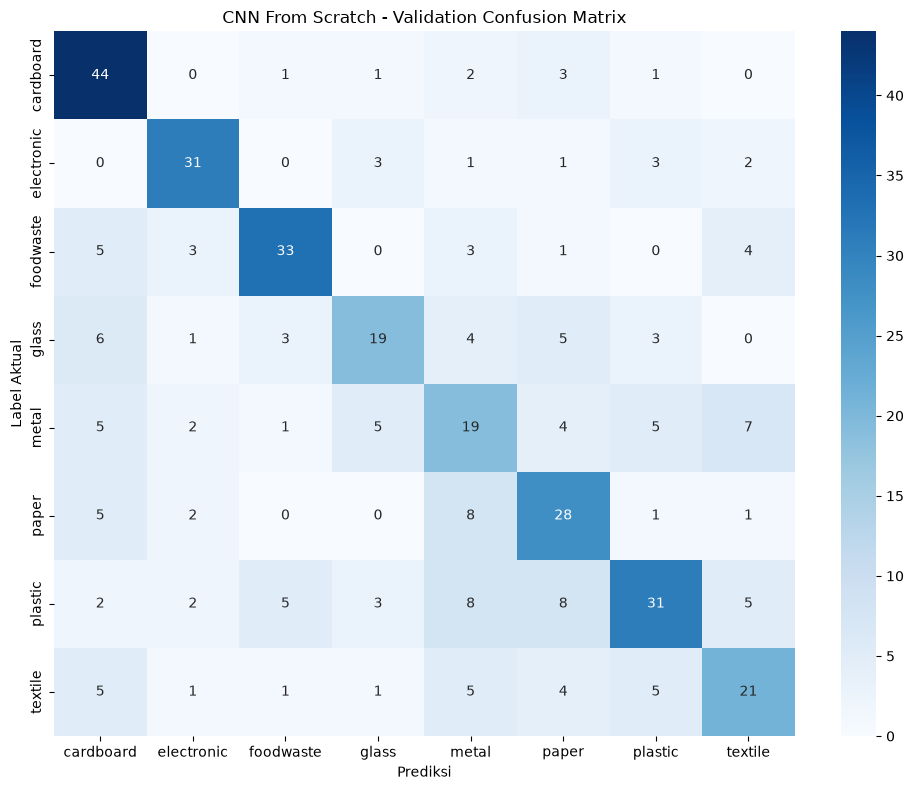

In [22]:
from IPython.display import display

if validation_metrics is not None:
    confusion = np.asarray(validation_metrics["confusion_matrix"])

    fig, ax = plt.subplots(figsize=(10, 8))

    sns.heatmap(
        confusion,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set_xlabel("Prediksi")
    ax.set_ylabel("Label Aktual")
    ax.set_title("CNN From Scratch - Validation Confusion Matrix")

    plt.tight_layout()
    display(fig)
    plt.close(fig)

else:
    print("Jalankan evaluasi validation terlebih dahulu.")

## 19. Overfitting / Underfitting Diagnostic

Diagnosis ini berbasis beberapa indikator dan bukan kesimpulan absolut. Ia membandingkan loss, accuracy gap, epoch terbaik, serta perubahan validation loss setelah epoch terbaik.

In [17]:
def diagnose_training(history: list[dict]) -> dict[str, object]:
    if not history:
        return {"status": "belum_tersedia", "message": "History nyata belum tersedia; diagnosis tidak dibuat."}
    frame = pd.DataFrame(history)
    best_index = frame["val_loss"].astype(float).idxmin()
    best_row, final_row = frame.loc[best_index], frame.iloc[-1]
    loss_gap = float(final_row["val_loss"] - final_row["train_loss"])
    accuracy_gap = float(final_row["train_accuracy"] - final_row["val_accuracy"])
    post_best_change = float(final_row["val_loss"] - best_row["val_loss"])
    indicators = []
    if loss_gap > 0.15 and accuracy_gap > 0.10 and post_best_change > 0:
        indicators.append("indikasi potensi overfitting; periksa tren beberapa epoch dan kelas yang sulit")
    if float(best_row["train_accuracy"]) < 0.55 and float(best_row["val_accuracy"]) < 0.55:
        indicators.append("indikasi potensi underfitting; periksa kapasitas model, data, dan learning rate")
    if not indicators:
        indicators.append("tidak ada indikator kuat dari aturan sederhana; interpretasikan bersama kurva dan confusion matrix")
    return {
        "best_epoch": int(best_row["epoch"]), "best_val_loss": float(best_row["val_loss"]),
        "final_train_val_loss_gap": loss_gap, "final_train_val_accuracy_gap": accuracy_gap,
        "val_loss_change_after_best": post_best_change, "indicators": indicators,
    }

if actual_history:
    display(pd.Series(diagnose_training(actual_history)))
else:
    print("Diagnosis menunggu metrics history aktual.")

best_epoch                                                                     64
best_val_loss                                                            1.248915
final_train_val_loss_gap                                                 0.280521
final_train_val_accuracy_gap                                             0.051341
val_loss_change_after_best                                               0.053575
indicators                      [tidak ada indikator kuat dari aturan sederhan...
dtype: object

## 20. Test Inference & Kaggle Submission

Validation (383 gambar) digunakan untuk monitoring dan pemilihan checkpoint, sedangkan internal test (191 gambar) tetap tidak dipakai pada section ini. Competition test resmi (480 gambar) hanya digunakan untuk inference submission dan harus berasal dari `data/competition/test/`. Nilai `waste_category` pada sample submission bukan label dan selalu diabaikan sebagai prediksi.

Cell berikut melakukan audit read-only data test dan checkpoint. Tidak ada inference atau CSV submission ketika `RUN_TEST_INFERENCE` tetap `False`.

In [8]:
from pathlib import Path
import sys

# Cari root proyek dari lokasi kerja notebook
current = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        path for path in [current, *current.parents]
        if (path / "src").is_dir()
        and (path / "configs").is_dir()
        and (path / "notebooks").is_dir()
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        f"Root proyek tidak ditemukan. Working directory: {current}"
    )

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("Folder src ditemukan:", (PROJECT_ROOT / "src").is_dir())

Project root: D:\FILE KULIAH\Lomba Gelar 2026\DSC_2026_Waste_Classification
Folder src ditemukan: True


In [11]:
from IPython.display import display

from src.inference.competition import (
    CompetitionTestDataset,
    audit_competition_test,
    create_competition_dataloader,
)
from src.inference.predict import load_cnn_best_checkpoint, predict_torch_classifier
from src.inference.submission import validate_submission_csv, write_submission_csv

RUN_TEST_INFERENCE = True
COMPETITION_TEST_DIR = PROJECT_ROOT / "data" / "competition" / "test"
SAMPLE_SUBMISSION_PATH = PROJECT_ROOT / "data" / "competition" / "SampleSubmission_DSC.csv"
CNN_BEST_CHECKPOINT_PATH = PROJECT_ROOT / "models" / "checkpoints" / EXPERIMENT_ID / "best.pt"
CNN_SUBMISSION_PATH = PROJECT_ROOT / "Final Dataset for Submission to Kaggle" / "submission_cnn_from_scratch.csv"
TEST_BATCH_SIZE = CONFIG["batch_size"]

competition_audit = audit_competition_test(
    project_root=PROJECT_ROOT,
    test_dir=COMPETITION_TEST_DIR,
    sample_submission_path=SAMPLE_SUBMISSION_PATH,
    expected_count=480,
)
display(pd.Series(competition_audit.to_dict()))

if not CNN_BEST_CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(f"Best checkpoint CNN tidak ditemukan: {CNN_BEST_CHECKPOINT_PATH}")
print(f"Best checkpoint siap untuk inference manual: {CNN_BEST_CHECKPOINT_PATH}")
print("Audit test resmi selesai. RUN_TEST_INFERENCE tetap False sehingga tidak ada prediksi atau CSV dibuat.")


NameError: name 'EXPERIMENT_ID' is not defined

### Manual Opt-In Inference

Ubah flag di atas menjadi `True` hanya setelah audit berhasil. Cell ini dapat dijalankan pada kernel baru setelah cell setup/configuration notebook dijalankan; ia membangun DataLoader test, memuat `best.pt`, dan mengambil class mapping dari checkpoint. Ia tidak membutuhkan hasil training yang masih tersimpan di memori kernel.

Output hanya ditulis ke `Final Dataset for Submission to Kaggle/submission_cnn_from_scratch.csv`. Penulisan memakai `overwrite=False` agar file CNN lama tidak tertimpa secara tidak sengaja dan tidak menyentuh file submission model lain.

In [ ]:
if RUN_TEST_INFERENCE:
    test_dataset = CompetitionTestDataset(
        model_type="cnn",
        project_root=PROJECT_ROOT,
        test_dir=COMPETITION_TEST_DIR,
        sample_submission_path=SAMPLE_SUBMISSION_PATH,
        expected_count=480,
    )
    test_loader = create_competition_dataloader(
        test_dataset,
        batch_size=TEST_BATCH_SIZE,
        num_workers=CONFIG["num_workers"],
        pin_memory=CONFIG["pin_memory"],
    )
    loaded_cnn = load_cnn_best_checkpoint(
        project_root=PROJECT_ROOT,
        checkpoint_path=CNN_BEST_CHECKPOINT_PATH,
        device=DEVICE,
    )
    assert loaded_cnn.model.training is False
    assert len(loaded_cnn.class_mapping) == 8

    competition_predictions = predict_torch_classifier(
        loaded_cnn.model,
        test_loader,
        index_to_class=loaded_cnn.index_to_class,
        device=loaded_cnn.device,
    )
    assert len(competition_predictions) == competition_audit.image_count == 480
    assert [prediction.image_id for prediction in competition_predictions] == list(test_dataset.template.image_ids)

    submission_path = write_submission_csv(
        test_dataset.template,
        competition_predictions,
        CNN_SUBMISSION_PATH,
        allowed_classes=loaded_cnn.class_mapping,
        overwrite=False,
    )
    validate_submission_csv(
        submission_path,
        test_dataset.template,
        allowed_classes=loaded_cnn.class_mapping,
    )

    submission_preview = pd.read_csv(submission_path, dtype={"image_id": str})
    display(submission_preview.head())
    display(submission_preview["waste_category"].value_counts().rename("prediction_count"))
    print(f"Validasi output selesai: {len(submission_preview)} prediksi tersimpan di {submission_path}")
else:
    print("Test inference tidak dijalankan. Set RUN_TEST_INFERENCE=True setelah audit data dan checkpoint ditinjau.")


## 21. Optional Resume Training Cell

Resume hanya memakai `last.pt` dari experiment ID yang sama, memulihkan model, optimizer, scheduler, AMP scaler, epoch, early stopping, history, serta RNG. Jangan resume otomatis setelah early stopping.

In [18]:
RUN_RESUME = False

if RUN_RESUME:
    if not manager.checkpoints.last_path.is_file():
        raise FileNotFoundError(f"Last checkpoint tidak ditemukan: {manager.checkpoints.last_path}")
    resume_scaler = torch.amp.GradScaler("cuda", enabled=CONFIG["amp_enabled"] and DEVICE.type == "cuda")
    resume_state = resume_from_checkpoint(
        manager.checkpoints.last_path, model, optimizer, scheduler=scheduler, scaler=resume_scaler,
        early_stopping=early_stopping, model_identifier="cnn_from_scratch", class_mapping=class_mapping,
        training_config=manager.training_config, map_location=DEVICE, restore_rng=True,
    )
    manager.scaler = resume_scaler
    manager.history = list(resume_state.history)
    manager.checkpoints.best_epoch = resume_state.best_epoch
    manager.checkpoints.best_metric = resume_state.best_metric
    print(f"Checkpoint dipulihkan. Lanjutkan secara manual mulai epoch {resume_state.start_epoch}.")
    # Untuk benar-benar melanjutkan, panggil manager.fit(..., start_epoch=resume_state.start_epoch) secara eksplisit.
else:
    print("Resume tidak dijalankan. Set RUN_RESUME=True hanya setelah meninjau last checkpoint.")

Resume tidak dijalankan. Set RUN_RESUME=True hanya setelah meninjau last checkpoint.


## 22. Optional Continued Training Cell

Untuk CNN from scratch, fase ini adalah continued training, bukan fine-tuning pretrained backbone. Fase baru memakai experiment ID baru, optimizer/scheduler/early stopping baru, dan learning rate lebih kecil. Internal test tidak digunakan sebagai dasar keputusan.

In [19]:
RUN_CONTINUED_TRAINING = False
CONTINUED_EXPERIMENT_ID = "cnn_scratch_continued_v1"
CONTINUED_LEARNING_RATE = 2e-4

if RUN_CONTINUED_TRAINING:
    if not manager.checkpoints.best_path.is_file():
        raise FileNotFoundError("Best checkpoint belum tersedia. Continued training tidak dapat dimulai.")
    phase_model = CNNFromScratch(num_classes=len(class_mapping), dropout=CONFIG["dropout"])
    lineage = load_best_checkpoint_for_fine_tuning(
        phase_model, str(manager.checkpoints.best_path), model_identifier="cnn_from_scratch", class_mapping=class_mapping,
    )
    phase_optimizer = torch.optim.AdamW(phase_model.parameters(), lr=CONTINUED_LEARNING_RATE, weight_decay=CONFIG["weight_decay"])
    phase_scheduler, phase_scheduler_kind = build_scheduler(phase_optimizer, SCHEDULER_CONFIG)
    phase_manager = TrainingManager(
        model=phase_model, optimizer=phase_optimizer, criterion=criterion, class_mapping=class_mapping,
        model_identifier="cnn_from_scratch", experiment_id=CONTINUED_EXPERIMENT_ID, project_root=PROJECT_ROOT,
        device=DEVICE, scheduler=phase_scheduler, scheduler_kind=phase_scheduler_kind,
        early_stopping=EarlyStopping(**EARLY_STOPPING_CONFIG),
        training_config={**CONFIG, "learning_rate": CONTINUED_LEARNING_RATE, "parent_experiment_id": EXPERIMENT_ID}, seed=SEED,
    )
    print({"continued_experiment_id": CONTINUED_EXPERIMENT_ID, **lineage})
    # Untuk menjalankan fase ini, panggil phase_manager.fit(train_loader, val_loader, max_epochs=...) secara eksplisit.
else:
    print("Continued training tidak dijalankan. Set RUN_CONTINUED_TRAINING=True setelah keputusan manual.")

Continued training tidak dijalankan. Set RUN_CONTINUED_TRAINING=True setelah keputusan manual.


## 23. Experiment Summary

1. Periksa environment, manifest, class mapping, dan preview sebelum training.
2. Jalankan training hanya melalui cell opt-in manual.
3. Gunakan validation untuk checkpoint, diagnosis, dan keputusan eksperimen.
4. Internal test tidak digunakan dalam notebook ini.
5. Gunakan experiment ID baru untuk eksperimen berbeda agar metrics, logs, dan checkpoint tidak saling menimpa.